## Assignment session 12: A new antibiotic
After initial prepwork, the two DataFrames need to be combined by merging on the smiles entry. After some processing, the cleaned data should be inspected via a quick EDA. The Hypothesis "lower lipophilicity leads to lower MIC" shall then be tested on the most effective compounds in the dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rdkit import Chem
from rdkit.Chem import Draw
from scipy import stats

Initial preparation before running the python script:

In [ ]:
df_raw = pd.read_csv("data/mics_raw.csv", sep=";", low_memory=False)
print(df_raw.shape)
df_raw.head()

In [ ]:
cols = ['Molecule ChEMBL ID', 'Smiles', 'Standard Type', 'Standard Relation',
        'Standard Value', 'Standard Units', 'Assay ChEMBL ID', 'Molecular Weight']
df = df_raw[cols].copy()

In [ ]:
# Renaming columns
df = df.rename(columns={
    'Molecule ChEMBL ID': 'chembl_id',
    'Smiles': 'canonical_smiles',
    'Standard Type': 'std_type',
    'Standard Relation': 'relation',
    'Standard Value': 'mic_value',
    'Standard Units': 'units',
    'Assay ChEMBL ID': 'assay_id',
    'Molecular Weight': 'mw_chembl',
})
df.info()

In [ ]:
# Without a SMILES string we cannot query PubChem or draw the molecule -> drop
n_before = len(df)
df = df.dropna(subset=['smiles'])
print(f"Dropped {n_before - len(df)} rows without SMILES")

In [ ]:
mw_min, mw_max = 0, 600   # change later to test the effect on your hypothesis
df = df[(df['mw_chembl'] >= mw_min) & (df['mw_chembl'] <= mw_max)]
print(df.shape)

In [ ]:
df_sample = df.sample(n=300, random_state=42)
df_sample.to_csv("chembl_sample.csv", index=False)

The actual task:

In [3]:
# Load both datasets
act = pd.read_csv("data/ecoli_mics.csv")
desc = pd.read_csv("data/antibio_pubchem_descr.csv")


Get an overview of data:

In [4]:
act.head(10)

,molecule_chembl_id,canonical_smiles,standard_type,standard_relation,standard_value,standard_units,assay_chembl_id
0,CHEMBL3621433,Cc1ccc(N(CC#N)Cc2ccc(F)cc2F)cc1,MIC,'=',128.00,ug.mL-1,CHEMBL3625335
1,CHEMBL4450418,N#C[C@@H]1CC[C@@H]2CN1C(=O)N2OS(=O)(=O)[O-].[Na+],MIC,'<=',0.12,ug.mL-1,CHEMBL5247824
2,CHEMBL2236659,O=C(/C=C/c1c(Cl)cccc1Cl)c1ccc[nH]1,MIC,'=',15.60,ug.mL-1,CHEMBL3061488
3,CHEMBL4127175,OB(O)c1ccc(Cn2cc(-c3ccccn3)nn2)cc1,MIC,'<=',0.03,ug.mL-1,CHEMBL4123733
4,CHEMBL296800,COc1cc2oc(-c3ccccc3)cc(=O)c2c(O)c1O,MIC,'>',125.00,ug.mL-1,CHEMBL682907
5,CHEMBL5414996,O=C(O)c1nccn1CCc1ccc([N+](=O)[O-])cc1,MIC,'=',8.00,ug.mL-1,CHEMBL5360869
6,CHEMBL575061,O=c1ccsn1-c1ccc(Cl)cc1,MIC,'=',10.00,ug.mL-1,CHEMBL1052821
7,CHEMBL5573576,O=C(Nc1ccccn1)c1ccc2c(c1)OCCCO2,MIC,'=',12.50,ug.mL-1,CHEMBL5529142
8,CHEMBL5416386,[C-]#[N+]c1ccc(NC(=O)Cc2c[nH]c3ccccc23)cc1,MIC,'>=',64000.00,nM,CHEMBL5355195
9,CHEMBL3275000,C=C(C)c1cnc([N+](=O)[O-])n1C,MIC,'>',100.00,ug.mL-1,CHEMBL3280883


In [5]:
act.info()

<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   molecule_chembl_id  300 non-null    str    
 1   canonical_smiles    299 non-null    str    
 2   standard_type       300 non-null    str    
 3   standard_relation   289 non-null    str    
 4   standard_value      289 non-null    float64
 5   standard_units      291 non-null    str    
 6   assay_chembl_id     300 non-null    str    
dtypes: float64(1), str(6)
memory usage: 37.6 KB


In [6]:
desc.head(10)

,canonical_smiles,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount
0,Cc1ccc(N(CC#N)Cc2ccc(F)cc2F)cc1,122191175.0,272.29,3.9,27.0,0.0,4.0,4.0,20.0
1,N#C[C@@H]1CC[C@@H]2CN1C(=O)N2OS(=O)(=O)[O-].[Na+],71535518.0,269.21,NaN,122.0,0.0,6.0,2.0,17.0
2,O=C(/C=C/c1c(Cl)cccc1Cl)c1ccc[nH]1,76329794.0,266.12,4.1,32.9,1.0,1.0,3.0,17.0
3,OB(O)c1ccc(Cn2cc(-c3ccccn3)nn2)cc1,145960871.0,280.09,NaN,84.1,2.0,5.0,4.0,21.0
4,COc1cc2oc(-c3ccccc3)cc(=O)c2c(O)c1O,471719.0,284.26,3.0,76.0,2.0,5.0,2.0,21.0
5,O=C(O)c1nccn1CCc1ccc([N+](=O)[O-])cc1,172452890.0,261.23,1.6,101.0,1.0,5.0,4.0,19.0
6,O=c1ccsn1-c1ccc(Cl)cc1,12368338.0,211.67,2.2,45.6,0.0,2.0,1.0,13.0
7,O=C(Nc1ccccn1)c1ccc2c(c1)OCCCO2,51251686.0,270.28,2.1,60.5,1.0,4.0,2.0,20.0
8,[C-]#[N+]c1ccc(NC(=O)Cc2c[nH]c3ccccc23)cc1,172451886.0,275.30,2.4,49.3,2.0,2.0,3.0,21.0
9,C=C(C)c1cnc([N+](=O)[O-])n1C,116559.0,167.17,1.3,63.6,0.0,3.0,1.0,12.0


In [7]:
desc.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   canonical_smiles    299 non-null    str    
 1   CID                 295 non-null    float64
 2   MolecularWeight     295 non-null    float64
 3   XLogP               274 non-null    float64
 4   TPSA                295 non-null    float64
 5   HBondDonorCount     295 non-null    float64
 6   HBondAcceptorCount  295 non-null    float64
 7   RotatableBondCount  295 non-null    float64
 8   HeavyAtomCount      295 non-null    float64
dtypes: float64(8), str(1)
memory usage: 31.4 KB


On the pubchemquery, drop duplicates:

In [10]:
print("Duplicated SMILES in PubChem data:", desc['canonical_smiles'].duplicated().sum())

# The same SMILES occurs several times in the ChEMBL data (different assays),
# so it was also queried several times. Keep only one row per SMILES before merging
# to avoid multiplying rows in the merge.
desc = desc.drop_duplicates(subset='canonical_smiles', keep='first')
print(desc.shape)

Duplicated SMILES in PubChem data: 55
(244, 9)


Combine the two datasets.

In [11]:
# Merge on canonical_smiles, how="inner" drops all rows which are only contained in one df
merged = pd.merge(act, desc, on="canonical_smiles", how="inner") 

print(f"Merged dataset: {len(merged)} entries")
print(merged.shape)
merged.head(10)

Merged dataset: 299 entries
(299, 15)


,molecule_chembl_id,canonical_smiles,standard_type,standard_relation,standard_value,standard_units,assay_chembl_id,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount
0,CHEMBL3621433,Cc1ccc(N(CC#N)Cc2ccc(F)cc2F)cc1,MIC,'=',128.00,ug.mL-1,CHEMBL3625335,122191175.0,272.29,3.9,27.0,0.0,4.0,4.0,20.0
1,CHEMBL4450418,N#C[C@@H]1CC[C@@H]2CN1C(=O)N2OS(=O)(=O)[O-].[Na+],MIC,'<=',0.12,ug.mL-1,CHEMBL5247824,71535518.0,269.21,NaN,122.0,0.0,6.0,2.0,17.0
2,CHEMBL2236659,O=C(/C=C/c1c(Cl)cccc1Cl)c1ccc[nH]1,MIC,'=',15.60,ug.mL-1,CHEMBL3061488,76329794.0,266.12,4.1,32.9,1.0,1.0,3.0,17.0
3,CHEMBL4127175,OB(O)c1ccc(Cn2cc(-c3ccccn3)nn2)cc1,MIC,'<=',0.03,ug.mL-1,CHEMBL4123733,145960871.0,280.09,NaN,84.1,2.0,5.0,4.0,21.0
4,CHEMBL296800,COc1cc2oc(-c3ccccc3)cc(=O)c2c(O)c1O,MIC,'>',125.00,ug.mL-1,CHEMBL682907,471719.0,284.26,3.0,76.0,2.0,5.0,2.0,21.0
5,CHEMBL5414996,O=C(O)c1nccn1CCc1ccc([N+](=O)[O-])cc1,MIC,'=',8.00,ug.mL-1,CHEMBL5360869,172452890.0,261.23,1.6,101.0,1.0,5.0,4.0,19.0
6,CHEMBL575061,O=c1ccsn1-c1ccc(Cl)cc1,MIC,'=',10.00,ug.mL-1,CHEMBL1052821,12368338.0,211.67,2.2,45.6,0.0,2.0,1.0,13.0
7,CHEMBL5573576,O=C(Nc1ccccn1)c1ccc2c(c1)OCCCO2,MIC,'=',12.50,ug.mL-1,CHEMBL5529142,51251686.0,270.28,2.1,60.5,1.0,4.0,2.0,20.0
8,CHEMBL5416386,[C-]#[N+]c1ccc(NC(=O)Cc2c[nH]c3ccccc23)cc1,MIC,'>=',64000.00,nM,CHEMBL5355195,172451886.0,275.30,2.4,49.3,2.0,2.0,3.0,21.0
9,CHEMBL3275000,C=C(C)c1cnc([N+](=O)[O-])n1C,MIC,'>',100.00,ug.mL-1,CHEMBL3280883,116559.0,167.17,1.3,63.6,0.0,3.0,1.0,12.0


Now, inspect the combined dataframe. Look for abnomalies, i.e. duplicates and missing data.

In [12]:
merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   molecule_chembl_id  299 non-null    str    
 1   canonical_smiles    299 non-null    str    
 2   standard_type       299 non-null    str    
 3   standard_relation   288 non-null    str    
 4   standard_value      288 non-null    float64
 5   standard_units      290 non-null    str    
 6   assay_chembl_id     299 non-null    str    
 7   CID                 295 non-null    float64
 8   MolecularWeight     295 non-null    float64
 9   XLogP               274 non-null    float64
 10  TPSA                295 non-null    float64
 11  HBondDonorCount     295 non-null    float64
 12  HBondAcceptorCount  295 non-null    float64
 13  RotatableBondCount  295 non-null    float64
 14  HeavyAtomCount      295 non-null    float64
dtypes: float64(9), str(6)
memory usage: 56.3 KB


One issue is the different units used:

In [13]:
merged["standard_value"].nlargest(20)

64     6900500.00
282    4340000.00
195    3100000.00
237    3019951.72
129    1247010.00
123    1028000.00
177    1027000.00
70     1000000.00
99      913000.00
77      868000.00
45      865000.00
82      856000.00
114     700000.00
156     430000.00
55      320000.00
39      313000.00
68      256000.00
280     225000.00
159     188000.00
14      160000.00
Name: standard_value, dtype: float64

In [15]:
merged['standard_units'].value_counts()

standard_units
ug.mL-1          245
nM                41
ug                 3
10'-2 umol/ml      1
Name: count, dtype: int64

Two options: Drop everything with units other than ug.L-1, or convert using molecular weight. Some of them might be corrupted and have to be dropped anyway. For simplicity, here is Option 1:

In [17]:
df_filtered = merged[merged['standard_units'] == 'ug.mL-1'].copy()
print(f"Option A: kept {len(df_filtered)} of {len(merged)} rows")

Option A: kept 245 of 299 rows


Run a quick EDA on the cleaned dataset including some plots. What can you conclude?

In [18]:
df_filtered.info()

<class 'pandas.DataFrame'>
Index: 245 entries, 0 to 298
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   molecule_chembl_id  245 non-null    str    
 1   canonical_smiles    245 non-null    str    
 2   standard_type       245 non-null    str    
 3   standard_relation   242 non-null    str    
 4   standard_value      242 non-null    float64
 5   standard_units      245 non-null    str    
 6   assay_chembl_id     245 non-null    str    
 7   CID                 243 non-null    float64
 8   MolecularWeight     243 non-null    float64
 9   XLogP               222 non-null    float64
 10  TPSA                243 non-null    float64
 11  HBondDonorCount     243 non-null    float64
 12  HBondAcceptorCount  243 non-null    float64
 13  RotatableBondCount  243 non-null    float64
 14  HeavyAtomCount      243 non-null    float64
dtypes: float64(9), str(6)
memory usage: 48.3 KB


In [ ]:
df_filtered.describe()

In [19]:
# Missing values
print(df_filtered.isna().sum())

molecule_chembl_id     0
canonical_smiles       0
standard_type          0
standard_relation      3
standard_value         3
standard_units         0
assay_chembl_id        0
CID                    2
MolecularWeight        2
XLogP                 23
TPSA                   2
HBondDonorCount        2
HBondAcceptorCount     2
RotatableBondCount     2
HeavyAtomCount         2
dtype: int64


In [20]:
# Bad data: non-positive or missing MIC values, missing descriptors
df_clean = df_filtered[df_filtered['standard_value'] > 0]
df_clean = df_clean.dropna(subset=['standard_value', 'XLogP'])   # adapt descriptor names
print(df_clean.shape)

(219, 15)


In [23]:
# Distribution of MIC (log scale, since MIC spans orders of magnitude)
df_clean['log_mic'] = np.log10(df_clean['standard_value'])

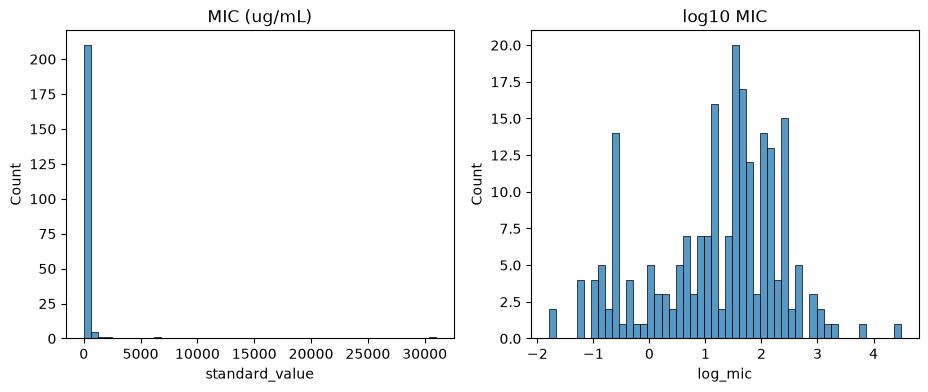

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df_clean['standard_value'], bins=50, ax=ax[0])
ax[0].set_title("MIC (ug/mL)")
sns.histplot(df_clean['log_mic'], bins=50, ax=ax[1])
ax[1].set_title("log10 MIC")
plt.show()

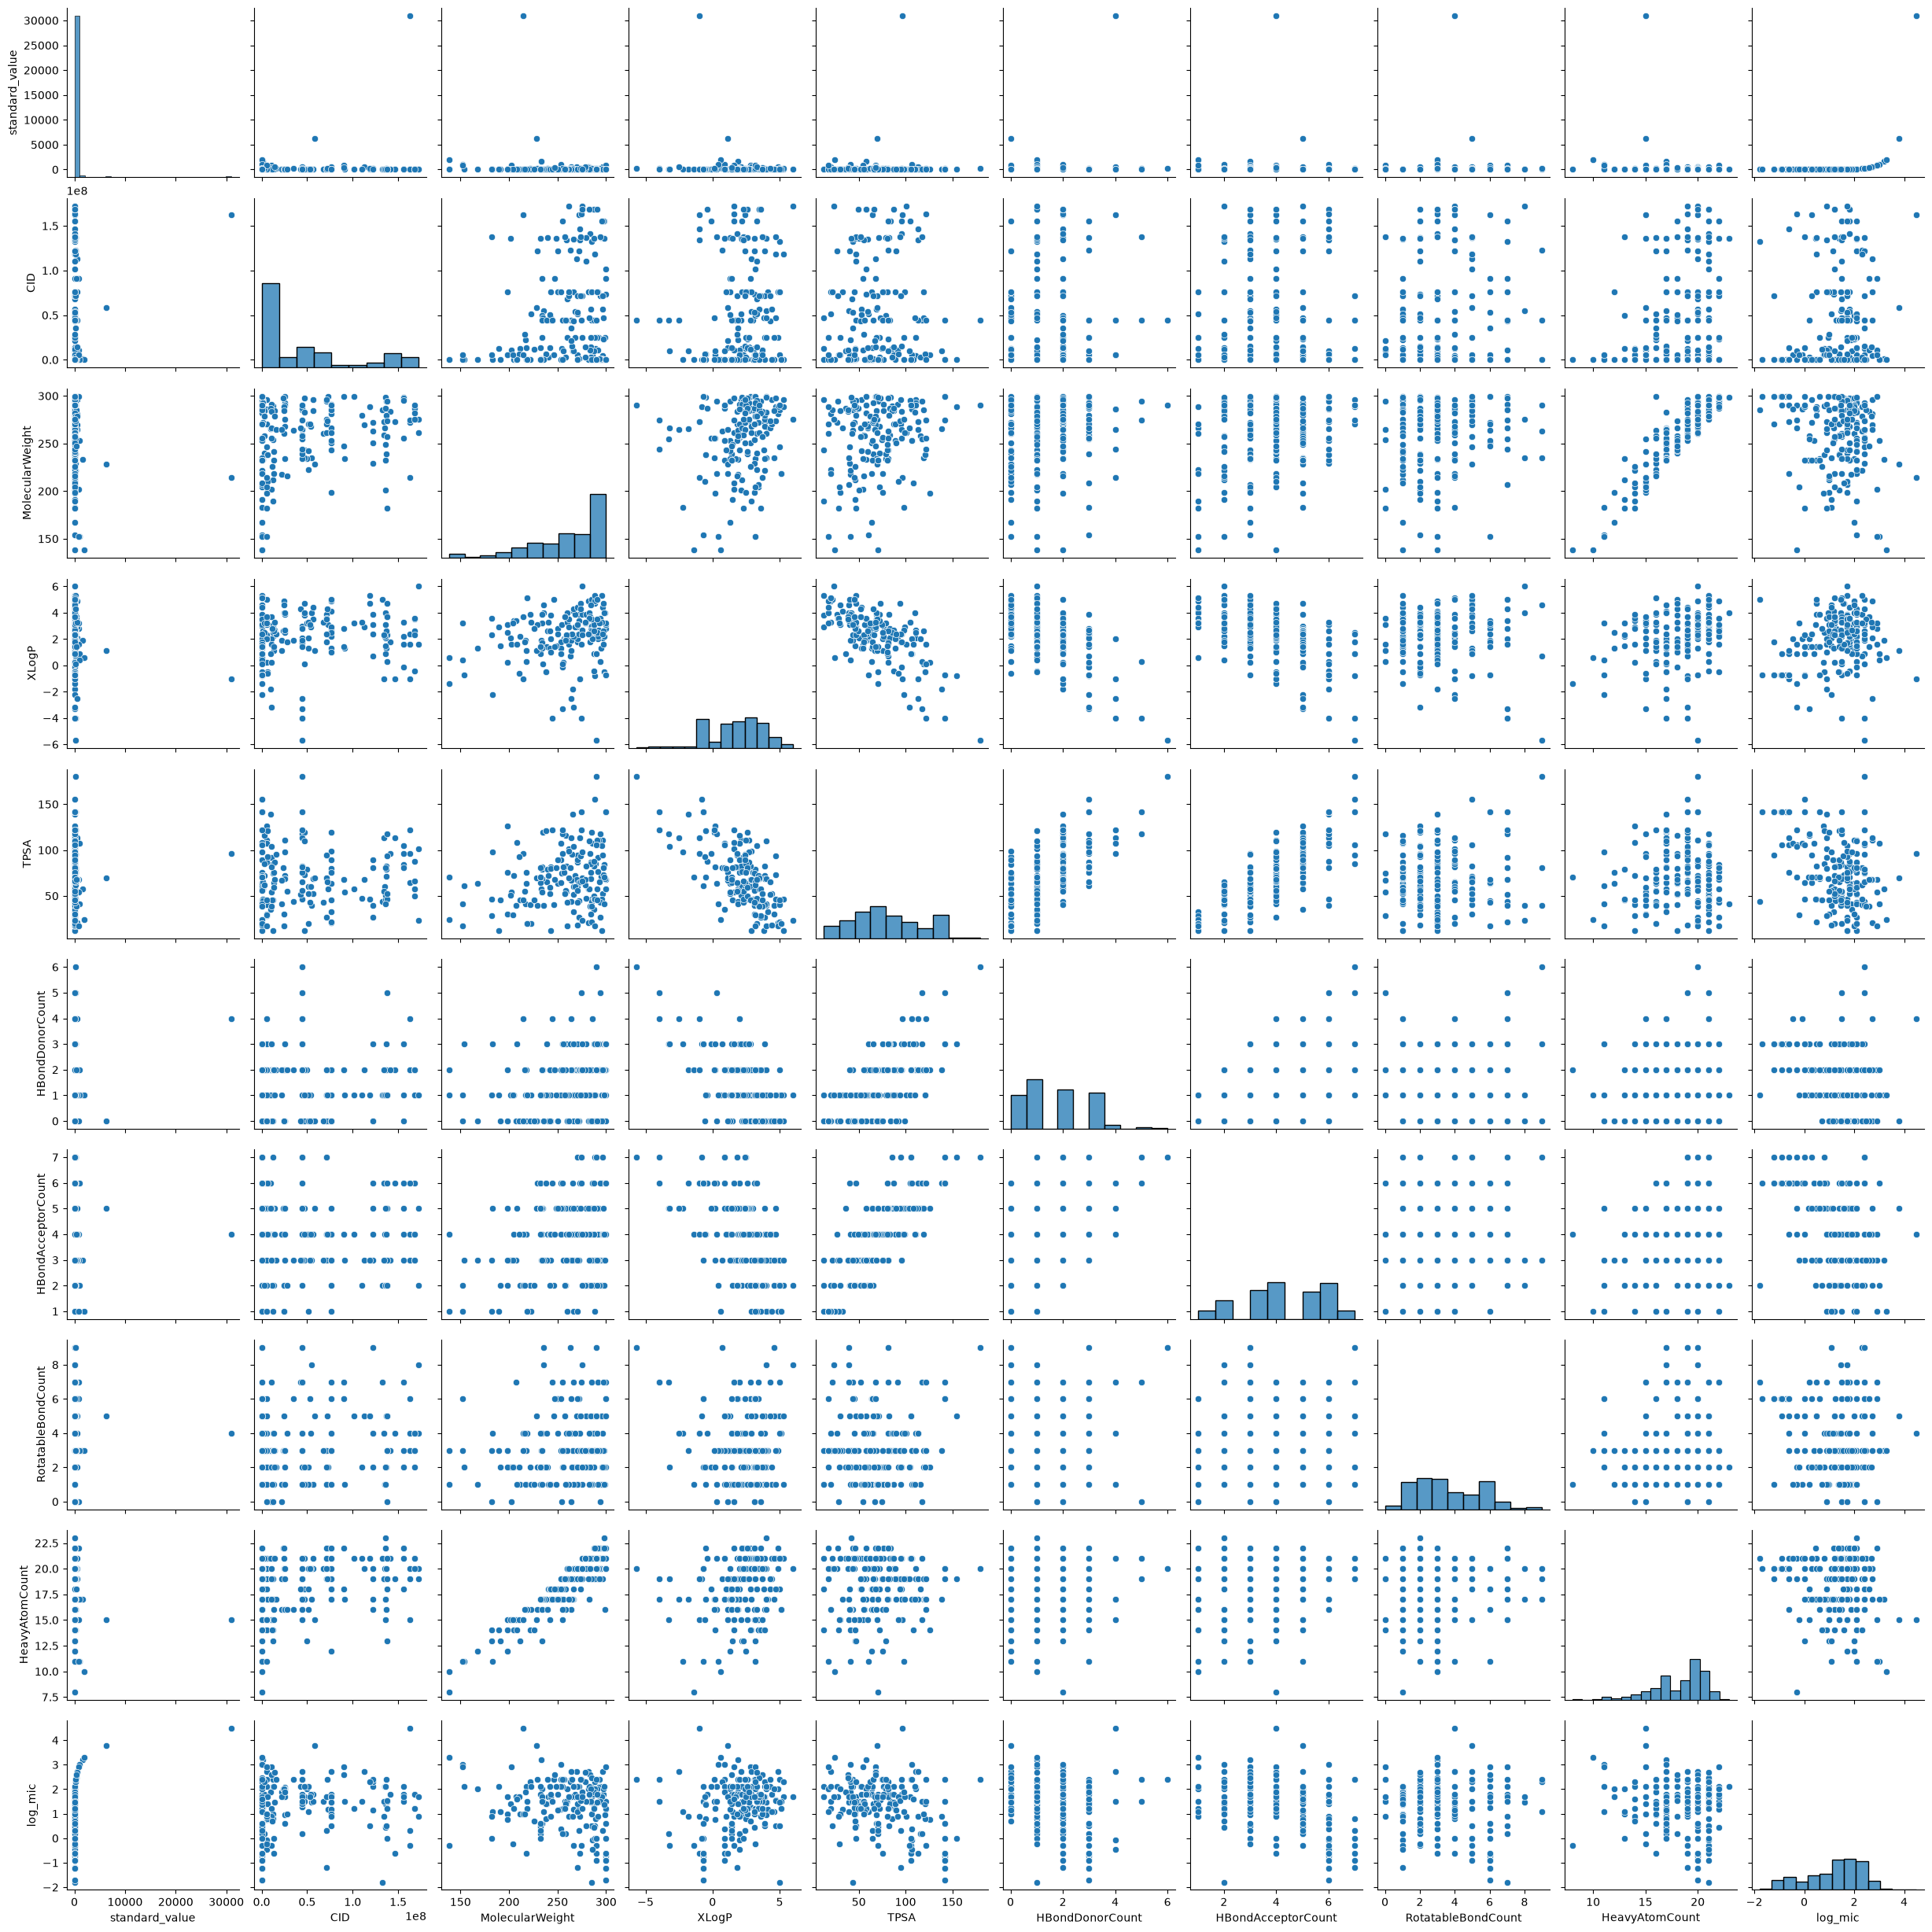

In [25]:
sns.pairplot(data=df_clean)
plt.show()

Filter from the dataframe all entries with a MIC < 10 (potential candidates as antibiotic) and visualise the 10 bes ones using rdkit.

In [26]:
df_filtered[df_filtered["standard_value"]<10]

,molecule_chembl_id,canonical_smiles,standard_type,standard_relation,standard_value,standard_units,assay_chembl_id,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount
1,CHEMBL4450418,N#C[C@@H]1CC[C@@H]2CN1C(=O)N2OS(=O)(=O)[O-].[Na+],MIC,'<=',0.120,ug.mL-1,CHEMBL5247824,71535518.0,269.21,NaN,122.0,0.0,6.0,2.0,17.0
3,CHEMBL4127175,OB(O)c1ccc(Cn2cc(-c3ccccn3)nn2)cc1,MIC,'<=',0.030,ug.mL-1,CHEMBL4123733,145960871.0,280.09,NaN,84.1,2.0,5.0,4.0,21.0
5,CHEMBL5414996,O=C(O)c1nccn1CCc1ccc([N+](=O)[O-])cc1,MIC,'=',8.000,ug.mL-1,CHEMBL5360869,172452890.0,261.23,1.6,101.0,1.0,5.0,4.0,19.0
16,CHEMBL1689063,NC(=O)[C@@H]1CC[C@@H]2CN1C(=O)N2OS(=O)(=O)O,MIC,'=',8.000,ug.mL-1,CHEMBL5259975,9835049.0,265.25,-1.8,139.0,2.0,6.0,3.0,17.0
19,CHEMBL4204019,CCCCCCc1ccc(-c2cn(C(C)C)c(N)n2)cc1,MIC,'=',0.016,ug.mL-1,CHEMBL4179301,132539946.0,285.40,5.0,43.8,1.0,2.0,7.0,21.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286,CHEMBL22,COc1cc(Cc2cnc(N)nc2N)cc(OC)c1OC,MIC,'<=',0.125,ug.mL-1,CHEMBL935006,5578.0,290.32,0.9,106.0,2.0,7.0,5.0,21.0
288,CHEMBL5,CCn1cc(C(=O)O)c(=O)c2ccc(C)nc21,MIC,'=',2.000,ug.mL-1,CHEMBL960519,4421.0,232.23,1.4,70.5,1.0,5.0,2.0,17.0
289,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C...,MIC,'=',0.250,ug.mL-1,CHEMBL1217823,104838.0,299.35,-0.7,142.0,3.0,6.0,6.0,20.0
293,CHEMBL148,C[C@@H](O)[C@H]1C(=O)N2C(C(=O)O)=C(SCCNC=N)C[C...,MIC,'=',0.125,ug.mL-1,CHEMBL1666096,104838.0,299.35,-0.7,142.0,3.0,6.0,6.0,20.0


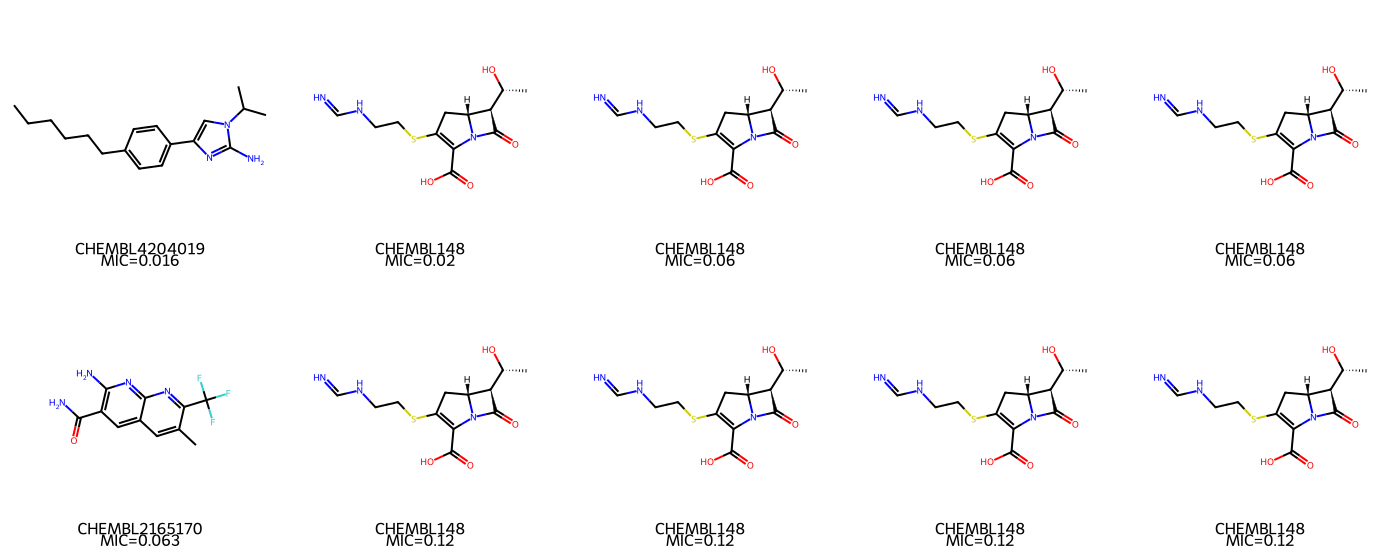

In [30]:
best = df_clean.nsmallest(10, 'standard_value')
mols = [Chem.MolFromSmiles(s) for s in best['canonical_smiles']]
legends = [f"{cid}\nMIC={v:.3g}" for cid, v in zip(best['molecule_chembl_id'], best['standard_value'])]

Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(280, 280), legends=legends)

Export the combined data.

In [31]:
df_clean.to_csv("data/ecoli_mic_clean.csv", index=False)

## Hypothesis testing

Since the MIC spreads over such a wide range, the logarithmic value is better to picture! Likewise for the non-logarithmic values, the distribution is extremely skewed and hence a few single values dominate both mean and variance. 

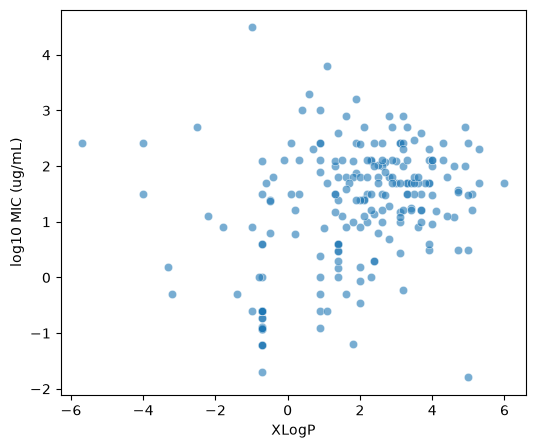

In [33]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=df_clean, x='XLogP', y='log_mic', alpha=0.6)
plt.xlabel("XLogP")
plt.ylabel("log10 MIC (ug/mL)")
plt.show()

Devide the population in two groups with higher and lower lipophilicity:

In [35]:
# Define high/low lipophilicity groups
df_clean["high_logp"] = df_clean["XLogP"] < 1
df_clean.head()

,molecule_chembl_id,canonical_smiles,standard_type,standard_relation,standard_value,standard_units,assay_chembl_id,CID,MolecularWeight,XLogP,TPSA,HBondDonorCount,HBondAcceptorCount,RotatableBondCount,HeavyAtomCount,log_mic,high_logp
0,CHEMBL3621433,Cc1ccc(N(CC#N)Cc2ccc(F)cc2F)cc1,MIC,'=',128.0,ug.mL-1,CHEMBL3625335,122191175.0,272.29,3.9,27.0,0.0,4.0,4.0,20.0,2.107210,False
2,CHEMBL2236659,O=C(/C=C/c1c(Cl)cccc1Cl)c1ccc[nH]1,MIC,'=',15.6,ug.mL-1,CHEMBL3061488,76329794.0,266.12,4.1,32.9,1.0,1.0,3.0,17.0,1.193125,False
4,CHEMBL296800,COc1cc2oc(-c3ccccc3)cc(=O)c2c(O)c1O,MIC,'>',125.0,ug.mL-1,CHEMBL682907,471719.0,284.26,3.0,76.0,2.0,5.0,2.0,21.0,2.096910,False
5,CHEMBL5414996,O=C(O)c1nccn1CCc1ccc([N+](=O)[O-])cc1,MIC,'=',8.0,ug.mL-1,CHEMBL5360869,172452890.0,261.23,1.6,101.0,1.0,5.0,4.0,19.0,0.903090,False
6,CHEMBL575061,O=c1ccsn1-c1ccc(Cl)cc1,MIC,'=',10.0,ug.mL-1,CHEMBL1052821,12368338.0,211.67,2.2,45.6,0.0,2.0,1.0,13.0,1.000000,False


Calculate the mean MIC, as well as std dev. and variance for the two groups

In [42]:
group_high = df_clean[df_clean["high_logp"]]["log_mic"]
group_low = df_clean[-df_clean["high_logp"]]["log_mic"]

print("size_high: ", group_high.size)
print("size_low: ", group_low.size, "\n")

mean_high = group_high.mean()
mean_low = group_low.mean()

print("mean_high: ", mean_high)
print("mean_low: ", mean_low, "\n")

var_high = group_high.var()
var_low = group_low.var()

print("var_high: ", var_high)
print("var_low: ", var_low)

size_high:  68
size_low:  151 

mean_high:  0.5475021905881761
mean_low:  1.4993547803585063 

var_high:  2.0601542382124336
var_low:  0.7005499125746458


Two sample t-test

In [43]:
# t-test

t_value, p_value = stats.ttest_ind(group_high, group_low, equal_var=False, nan_policy="omit")
print(f"t_value = {t_value:.2f}, p_value = {p_value:.9f}")

t_value = -5.09, p_value = 0.000001986
